# Unified Live Demo: Baseline CVP/ANP vs. Proposed VA-ANP

Direct comparison on simulated ML-KEM-style q-ary lattices (`q = 3329`).

Run the cells from top to bottom. The final cell prints aggregate results and displays the comparison plots.

In [ ]:
import numpy as np
from numpy.linalg import norm
import time
import matplotlib.pyplot as plt

np.random.seed(42)

## 1. Shared lattice generation and basis reduction

In [ ]:
def gram_schmidt(B):
    """Gram-Schmidt orthogonalization (rows of B are basis vectors)."""
    n = B.shape[0]
    B_star = np.zeros_like(B, dtype=float)
    mu = np.zeros((n, n), dtype=float)
    nrm_sq = np.zeros(n, dtype=float)

    for i in range(n):
        v = B[i].astype(float).copy()
        for j in range(i):
            if nrm_sq[j] > 1e-12:
                mu[i, j] = np.dot(B[i], B_star[j]) / nrm_sq[j]
                v -= mu[i, j] * B_star[j]
        B_star[i] = v
        nrm_sq[i] = np.dot(v, v)

    return B_star, mu, nrm_sq


def lll_reduce(B, delta=0.99):
    """LLL lattice basis reduction."""
    n = B.shape[0]
    B = B.astype(float).copy()
    B_star, mu, nrm_sq = gram_schmidt(B)

    k = 1
    while k < n:
        for j in range(k - 1, -1, -1):
            if abs(mu[k, j]) > 0.5:
                B[k] -= round(mu[k, j]) * B[j]
                B_star, mu, nrm_sq = gram_schmidt(B)

        if nrm_sq[k] >= (delta - mu[k, k - 1] ** 2) * nrm_sq[k - 1]:
            k += 1
        else:
            B[[k, k - 1]] = B[[k - 1, k]]
            B_star, mu, nrm_sq = gram_schmidt(B)
            k = max(k - 1, 1)

    return B, B_star, mu, nrm_sq


def generate_qary_lattice(n, q=3329):
    """Generate a q-ary lattice basis with a simple block structure."""
    k = n // 2
    A = np.random.randint(0, q, size=(n - k, k))
    B = np.zeros((n, n), dtype=float)
    B[:k, :k] = q * np.eye(k)
    B[k:, :k] = A
    B[k:, k:] = np.eye(n - k)
    return B


def generate_bdd_instance(B_reduced, sigma):
    """Generate target = lattice point + Gaussian noise."""
    n = B_reduced.shape[0]
    coeffs = np.random.randint(-3, 4, size=n)
    lattice_point = coeffs @ B_reduced
    noise = np.random.normal(0.0, sigma, size=n)
    target = lattice_point + noise
    return target, lattice_point

## 2. Classical baselines and Code 1 algorithms

In [ ]:
def babai_roundoff(B, target):
    """Babai round-off baseline."""
    start = time.perf_counter()
    coords = np.linalg.solve(B.T, target)
    closest = np.round(coords) @ B
    return closest, time.perf_counter() - start


def babai_nearest_plane(B, B_star, nrm_sq, target):
    """Standard Babai nearest-plane algorithm."""
    start = time.perf_counter()
    b = target.astype(float).copy()
    for i in range(B.shape[0] - 1, -1, -1):
        if nrm_sq[i] < 1e-12:
            continue
        c = np.dot(b, B_star[i]) / nrm_sq[i]
        b -= round(c) * B[i]
    return target - b, time.perf_counter() - start


def code1_lp_original(B, B_star, nrm_sq, target, num_planes=3, max_list=None):
    """Code 1's original LP candidate expansion."""
    start = time.perf_counter()
    n = B.shape[0]
    if max_list is None:
        max_list = 2 * n

    candidates = [(target.astype(float).copy(), 0.0)]
    for i in range(n - 1, -1, -1):
        if nrm_sq[i] < 1e-12:
            continue
        b_star_i = B_star[i]
        nsq = nrm_sq[i]
        new_candidates = []

        for b, acc_dist in candidates:
            c = np.dot(b, b_star_i) / nsq
            c_round = round(c)
            frac = c - c_round
            choices = [c_round]
            if frac >= 0:
                for offset in range(1, num_planes):
                    choices.append(c_round + offset)
            else:
                for offset in range(1, num_planes):
                    choices.append(c_round - offset)

            for c_try in choices[:num_planes]:
                d = ((c - c_try) ** 2) * nsq
                new_candidates.append((b - c_try * B[i], acc_dist + d))

        new_candidates.sort(key=lambda x: x[1])
        candidates = new_candidates[:max_list]

    best_b, _ = min(candidates, key=lambda x: np.dot(x[0], x[0]))
    return target - best_b, time.perf_counter() - start


def code1_anp_fractional(B, B_star, nrm_sq, target,
                         ambiguity_threshold=0.35, max_list=None):
    """Code 1 fractional-only adaptive nearest planes."""
    start = time.perf_counter()
    n = B.shape[0]
    if max_list is None:
        max_list = 2 * n

    candidates = [(target.astype(float).copy(), 0.0)]
    stats = {"nodes": 0, "children": 0}

    for i in range(n - 1, -1, -1):
        if nrm_sq[i] < 1e-12:
            continue
        b_star_i = B_star[i]
        nsq = nrm_sq[i]
        new_candidates = []

        for b, acc_dist in candidates:
            stats["nodes"] += 1
            c = np.dot(b, b_star_i) / nsq
            c_round = round(c)
            frac = c - c_round
            ambiguity = 2.0 * abs(frac)

            if ambiguity <= ambiguity_threshold:
                choices = [c_round]
            else:
                choices = [c_round, c_round + (1 if frac >= 0 else -1)]

            for c_try in choices:
                stats["children"] += 1
                d = ((c - c_try) ** 2) * nsq
                new_candidates.append((b - c_try * B[i], acc_dist + d))

        if len(new_candidates) > max_list:
            new_candidates.sort(key=lambda x: x[1])
            candidates = new_candidates[:max_list]
        else:
            candidates = new_candidates

    best_b, _ = min(candidates, key=lambda x: np.dot(x[0], x[0]))
    return target - best_b, time.perf_counter() - start, stats

## 3. Code 2 algorithms: fixed LP and proposed VA-ANP

In [ ]:
def schnorr_euchner_planes(c, num_planes):
    """Return integer candidates in zig-zag order around c."""
    c_round = int(round(c))
    frac = c - c_round
    step = 1 if frac >= 0 else -1
    planes = [c_round]
    offset = 1
    while len(planes) < num_planes:
        planes.append(c_round + step * offset)
        if len(planes) < num_planes:
            planes.append(c_round - step * offset)
        offset += 1
    return planes


def code2_lp_fixed(B, B_star, nrm_sq, target, num_planes=2, max_list=None):
    """Corrected LP with Schnorr-Euchner candidate ordering."""
    start = time.perf_counter()
    n = B.shape[0]
    if max_list is None:
        max_list = 2 * n

    candidates = [(target.astype(float).copy(), 0.0)]
    for i in range(n - 1, -1, -1):
        if nrm_sq[i] < 1e-12:
            continue
        b_star_i = B_star[i]
        nsq = nrm_sq[i]
        new_candidates = []

        for b, acc_dist in candidates:
            c = np.dot(b, b_star_i) / nsq
            for c_try in schnorr_euchner_planes(c, num_planes):
                d = ((c - c_try) ** 2) * nsq
                new_candidates.append((b - c_try * B[i], acc_dist + d))

        if len(new_candidates) > max_list:
            new_candidates.sort(key=lambda x: x[1])
            candidates = new_candidates[:max_list]
        else:
            candidates = new_candidates

    best_b, _ = min(candidates, key=lambda x: np.dot(x[0], x[0]))
    return target - best_b, time.perf_counter() - start


def code2_variance_aware_anp(B, B_star, nrm_sq, target, sigma,
                             llr_threshold=2.2, sphere_mult=2.8, max_list=None):
    """Proposed variance-aware adaptive nearest planes (VA-ANP)."""
    start = time.perf_counter()
    n = B.shape[0]
    if max_list is None:
        max_list = 2 * n

    two_sigma_sq = 2.0 * (sigma ** 2)
    max_penalty = llr_threshold * two_sigma_sq
    sphere_radius_sq = sphere_mult * n * (sigma ** 2)

    candidates = [(target.astype(float).copy(), 0.0)]
    stats = {"nodes": 0, "children": 0}

    for i in range(n - 1, -1, -1):
        if nrm_sq[i] < 1e-12:
            continue
        b_star_i = B_star[i]
        nsq = nrm_sq[i]
        new_candidates = []

        for b, acc_dist in candidates:
            stats["nodes"] += 1
            c = np.dot(b, b_star_i) / nsq
            se_planes = schnorr_euchner_planes(c, 3)
            d0 = ((c - se_planes[0]) ** 2) * nsq

            if acc_dist + d0 <= sphere_radius_sq or len(new_candidates) == 0:
                new_candidates.append((b - se_planes[0] * B[i], acc_dist + d0))
                stats["children"] += 1

            for m_k in se_planes[1:]:
                dk = ((c - m_k) ** 2) * nsq
                excess_dist_sq = dk - d0
                if excess_dist_sq <= max_penalty and (acc_dist + dk) <= sphere_radius_sq:
                    new_candidates.append((b - m_k * B[i], acc_dist + dk))
                    stats["children"] += 1
                else:
                    break

        if not new_candidates:
            b, acc_dist = candidates[0]
            c = np.dot(b, B_star[i]) / nrm_sq[i]
            m0 = round(c)
            d0 = ((c - m0) ** 2) * nrm_sq[i]
            new_candidates.append((b - m0 * B[i], acc_dist + d0))

        if len(new_candidates) > max_list:
            new_candidates.sort(key=lambda x: x[1])
            candidates = new_candidates[:max_list]
        else:
            candidates = new_candidates

    best_b, _ = min(candidates, key=lambda x: np.dot(x[0], x[0]))
    return target - best_b, time.perf_counter() - start, stats

## 4. Head-to-head benchmark and visualization

This cell runs 360 BDD instances (`4 dimensions × 3 noise ratios × 30 trials`).

HEAD-TO-HEAD BENCHMARK: Code 1 vs. Proposed VA-ANP

FINAL AGGREGATE COMPARISON (360 Total BDD Trials)
Algorithm                     Exact Recovery   Avg Error    Avg Time   Planes/Node
----------------------------------------------------------------------------------
1. Babai-RO (Base)                     32.5%       59.98     0.045ms         1.00x
2. Babai-NP (Base)                     58.9%       35.91     0.067ms         1.00x
3. LP k=2 (Standard)                   70.3%       25.35     1.923ms         2.00x
4. Code1-LP k=3 (Buggy)                70.3%       25.35     2.813ms         3.00x
5. Code2-LP k=3 (Fixed)                70.0%       25.58     2.788ms         3.00x
6. Code1-ANP (Frac Only)               70.3%       25.35     1.315ms         1.63x
7. Code2-VA-ANP (Proposed)             70.0%       25.55     0.502ms         1.17x

KEY TAKEAWAYS (computed from this run):
1. LP(k=3) exact recovery: original=70.3% vs fixed=70.0%.
2. VA-ANP vs Code 1 ANP: 70.0% vs 70.3% exact recove

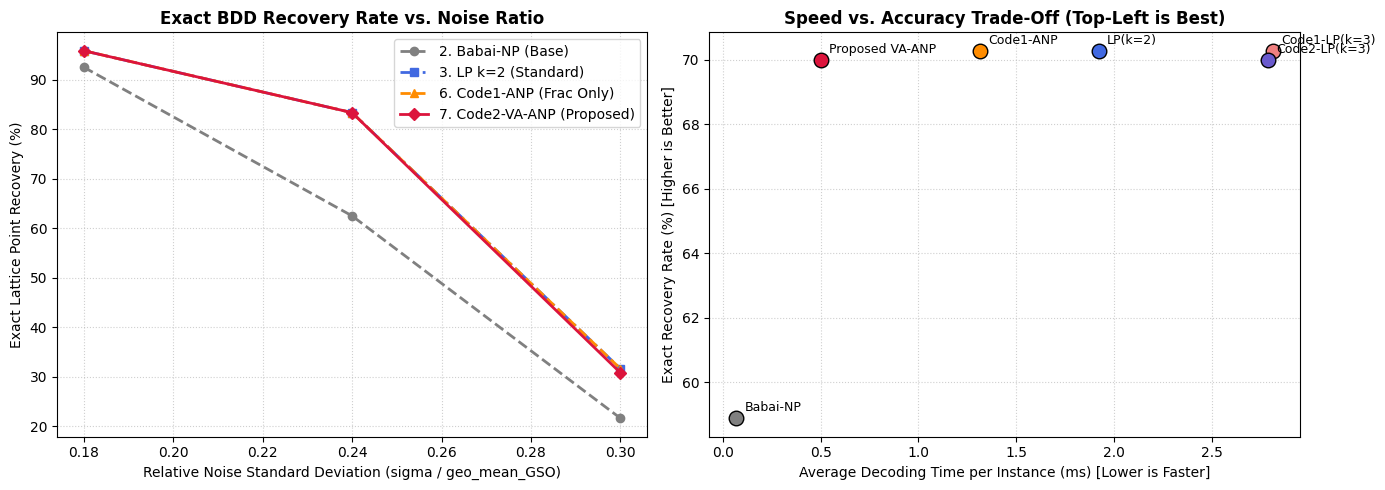

In [ ]:
def run_head_to_head():
    print("=" * 88)
    print("HEAD-TO-HEAD BENCHMARK: Code 1 vs. Proposed VA-ANP")
    print("=" * 88)

    dimensions = [10, 12, 14, 16]
    noise_ratios = [0.18, 0.24, 0.30]
    num_trials = 30
    q = 3329

    algo_names = [
        "1. Babai-RO (Base)",
        "2. Babai-NP (Base)",
        "3. LP k=2 (Standard)",
        "4. Code1-LP k=3 (Buggy)",
        "5. Code2-LP k=3 (Fixed)",
        "6. Code1-ANP (Frac Only)",
        "7. Code2-VA-ANP (Proposed)"
    ]

    summary = {name: {"exact": 0, "dist": [], "time": [], "exp": []} for name in algo_names}
    by_noise = {r: {name: 0 for name in algo_names} for r in noise_ratios}
    total_runs = len(dimensions) * len(noise_ratios) * num_trials

    for dim in dimensions:
        for ratio in noise_ratios:
            for _ in range(num_trials):
                B_raw = generate_qary_lattice(dim, q)
                B_lll, B_star, mu, nrm_sq = lll_reduce(B_raw)
                geo_mean_gs = np.exp(0.5 * np.mean(np.log(nrm_sq)))
                sigma = ratio * geo_mean_gs
                target, true_pt = generate_bdd_instance(B_lll, sigma)

                res = {}
                v, t = babai_roundoff(B_lll, target)
                res[algo_names[0]] = (v, t, 1.0)

                v, t = babai_nearest_plane(B_lll, B_star, nrm_sq, target)
                res[algo_names[1]] = (v, t, 1.0)

                v, t = code2_lp_fixed(B_lll, B_star, nrm_sq, target, num_planes=2)
                res[algo_names[2]] = (v, t, 2.0)

                v, t = code1_lp_original(B_lll, B_star, nrm_sq, target, num_planes=3)
                res[algo_names[3]] = (v, t, 3.0)

                v, t = code2_lp_fixed(B_lll, B_star, nrm_sq, target, num_planes=3)
                res[algo_names[4]] = (v, t, 3.0)

                v, t, st1 = code1_anp_fractional(B_lll, B_star, nrm_sq, target, 0.35)
                res[algo_names[5]] = (v, t, st1["children"] / max(st1["nodes"], 1))

                v, t, st2 = code2_variance_aware_anp(B_lll, B_star, nrm_sq, target, sigma)
                res[algo_names[6]] = (v, t, st2["children"] / max(st2["nodes"], 1))

                for name, (v_hat, elapsed, exp_f) in res.items():
                    d = norm(v_hat - true_pt)
                    is_exact = int(d < 1e-3)
                    summary[name]["exact"] += is_exact
                    summary[name]["dist"].append(d)
                    summary[name]["time"].append(elapsed)
                    summary[name]["exp"].append(exp_f)
                    by_noise[ratio][name] += is_exact

    print("\n" + "=" * 88)
    print(f"FINAL AGGREGATE COMPARISON ({total_runs} Total BDD Trials)")
    print("=" * 88)
    print(f"{'Algorithm':<28} {'Exact Recovery':>15} {'Avg Error':>11} {'Avg Time':>11} {'Planes/Node':>13}")
    print("-" * 82)

    for name in algo_names:
        s = summary[name]
        ex_pct = s["exact"] / total_runs * 100
        avg_d = np.mean(s["dist"])
        avg_t = np.mean(s["time"]) * 1000
        avg_exp = np.mean(s["exp"])
        print(f"{name:<28} {ex_pct:>14.1f}% {avg_d:>11.2f} {avg_t:>9.3f}ms {avg_exp:>12.2f}x")

    c1_acc = summary[algo_names[5]]["exact"] / total_runs * 100
    c2_acc = summary[algo_names[6]]["exact"] / total_runs * 100
    c1_time = np.mean(summary[algo_names[5]]["time"]) * 1000
    c2_time = np.mean(summary[algo_names[6]]["time"]) * 1000

    print("\n" + "=" * 88)
    print("KEY TAKEAWAYS (computed from this run):")
    buggy_acc = summary[algo_names[3]]["exact"] / total_runs * 100
    fixed_acc = summary[algo_names[4]]["exact"] / total_runs * 100
    lp3_acc = fixed_acc
    print(f"1. LP(k=3) exact recovery: original={buggy_acc:.1f}% vs fixed={fixed_acc:.1f}%.")
    speedup = c1_time / c2_time if c2_time > 0 else float('inf')
    print(f"2. VA-ANP vs Code 1 ANP: {c2_acc:.1f}% vs {c1_acc:.1f}% exact recovery; time speedup={speedup:.2f}x.")
    print(f"3. VA-ANP vs fixed 3-plane LP: {c2_acc:.1f}% vs {lp3_acc:.1f}% exact recovery.")
    print("=" * 88)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    plot_algos = [
        (algo_names[1], "gray", "--", "o"),
        (algo_names[2], "royalblue", "-.", "s"),
        (algo_names[5], "darkorange", "--", "^"),
        (algo_names[6], "crimson", "-", "D"),
    ]
    trials_per_noise = len(dimensions) * num_trials
    for name, color, ls, marker in plot_algos:
        rates = [by_noise[r][name] / trials_per_noise * 100 for r in noise_ratios]
        ax1.plot(noise_ratios, rates, label=name, color=color,
                 linestyle=ls, marker=marker, linewidth=2)

    ax1.set_title("Exact BDD Recovery Rate vs. Noise Ratio", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Relative Noise Standard Deviation (sigma / geo_mean_GSO)")
    ax1.set_ylabel("Exact Lattice Point Recovery (%)")
    ax1.grid(True, linestyle=":", alpha=0.6)
    ax1.legend()

    short_labels = ["Babai-NP", "LP(k=2)", "Code1-LP(k=3)",
                    "Code2-LP(k=3)", "Code1-ANP", "Proposed VA-ANP"]
    selected_keys = algo_names[1:]
    colors = ["gray", "royalblue", "lightcoral", "slateblue", "darkorange", "crimson"]
    for lbl, key, col in zip(short_labels, selected_keys, colors):
        t_ms = np.mean(summary[key]["time"]) * 1000
        acc = summary[key]["exact"] / total_runs * 100
        ax2.scatter(t_ms, acc, color=col, s=110, label=lbl,
                    edgecolors="black", zorder=3)
        ax2.annotate(lbl, (t_ms, acc), textcoords="offset points",
                     xytext=(6, 5), fontsize=9)

    ax2.set_title("Speed vs. Accuracy Trade-Off (Top-Left is Best)", fontsize=12, fontweight="bold")
    ax2.set_xlabel("Average Decoding Time per Instance (ms) [Lower is Faster]")
    ax2.set_ylabel("Exact Recovery Rate (%) [Higher is Better]")
    ax2.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.savefig("cvp_comparison_results.png", dpi=150)
    plt.show()


run_head_to_head()